# testing waveform

In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
t = np.array([-1.0526e-03, -9.2963e-04,  0.0000e+00,  2.5000e-06])
wv = np.array([0, 1, 1, 0])

In [10]:
from anemone.transforms import Hankel, invFourier, CubicSpline
from anemone.physics import refl_transverse_electric as rte, freespace_u0 as u0
from anemone import constants as c
from anemone.experiment import Loop, Receiver, integrate_around_loop, Waveform

import torch

class Forward:
    def __init__(self, source, receiver, times, waveform):
        self.source = source
        self.receiver = receiver
        self.times = torch.tensor(times)
        self.rmin = self.source.min_horizontal_distance(self.receiver)
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.dz = torch.tensor(self.receiver.z+self.source.z[0])
        self.waveform = waveform
    
    @property
    def wv(self):
        return self.waveform

    def forward(self):
        def frq_integrand(f):
            omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                lmb = wave_length[None, None, :]
                tmp_u0 = u0(omega, lmb)
                intg = torch.squeeze((torch.exp(-tmp_u0*self.dz)*rte(self.sigma, self.thick, omega, lmb))*lmb**2 / (tmp_u0*1j*omega))
                return -intg/c.fourpi
            hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=20, range=(self.rmin, self.rmax))
            return integrate_around_loop(self.source, self.receiver, hkl1)
        ift=invFourier(frq_integrand, smp_per_decade=20)
        cbft = CubicSpline(*ift.range(self.times[0]-self.wv.time.max(), self.times[-1]-self.wv.time.min()), transform=torch.log10)
        t_eval = self.times[:, None] - self.wv.time[None, :]
        resp_step = cbft(t_eval).real
        return resp_step @ self.waveform.d2wdt2

    def __call__(self, sigma, thickness):
        self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
        self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]
        return self.forward()*c.mu0

In [11]:
# slope = np.diff(wv)/np.diff(t)

# d2wdt2 = np.zeros_like(t)
# d2wdt2[1:-1] = np.diff(slope)
# d2wdt2[0] = slope[0]
# d2wdt2[-1] = -slope[-1]

times = np.array([9.350e-06, 1.145e-05, 1.458e-05, 1.822e-05, 2.255e-05, 2.867e-05,
       3.595e-05, 4.460e-05, 5.660e-05, 7.070e-05, 8.630e-05, 1.071e-04,
       1.381e-04, 1.748e-04, 2.174e-04, 2.775e-04, 3.515e-04, 4.385e-04,
       5.575e-04, 7.035e-04])

In [12]:
lp = Loop.square(40)
rx = Receiver()
waveform = Waveform(t, wv)
fwr = Forward(lp, rx, times, waveform)

C:\Users\au646858\AppData\Local\Temp\ipykernel_16672\3869063952.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.dz = torch.tensor(self.receiver.z+self.source.z[0])


In [13]:
rho = 40
sigma = 1/torch.tensor([rho,rho])
thick = torch.tensor([10])
dbdt = fwr(sigma, thick)

C:\Users\au646858\AppData\Local\Temp\ipykernel_16672\3869063952.py:39: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
C:\Users\au646858\AppData\Local\Temp\ipykernel_16672\3869063952.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]


In [14]:
dbdt

tensor([3.8522e-04, 2.3082e-04, 1.2552e-04, 7.1658e-05, 4.1949e-05, 2.2969e-05,
        1.3026e-05, 7.5901e-06, 4.1789e-06, 2.3939e-06, 1.4527e-06, 8.4545e-07,
        4.4663e-07, 2.4686e-07, 1.4236e-07, 7.6646e-08, 4.1890e-08, 2.3672e-08,
        1.2636e-08, 6.8088e-09], dtype=torch.float64)

In [15]:
ainv_dbdt = np.array([3.853627e-04, 2.309149e-04, 1.255715e-04, 7.168451e-05,
       4.196206e-05, 2.297534e-05, 1.302996e-05, 7.591422e-06,
       4.179841e-06, 2.394241e-06, 1.452859e-06, 8.455657e-07,
       4.466630e-07, 2.468966e-07, 1.423754e-07, 7.665493e-08,
       4.189503e-08, 2.367454e-08, 1.263738e-08, 6.809730e-09])

Text(0, 0.5, 'relative difference [%]')

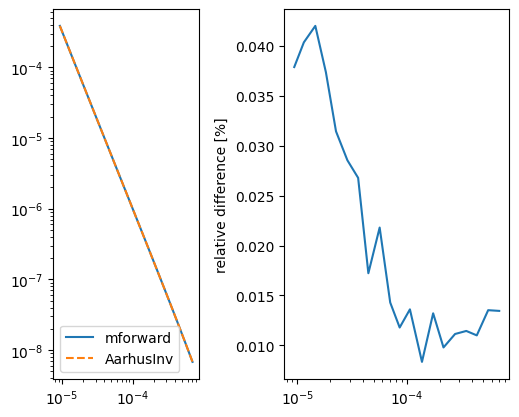

In [16]:
fig,ax = plt.subplots(1,2, sharex=True)
ax[0].loglog(fwr.times.numpy(), dbdt.real, label='mforward')
ax[0].loglog(times,      ainv_dbdt, '--', label='AarhusInv')
ax[0].legend()
ax[0].set_aspect('equal')

ax[1].semilogx(times, 100*np.abs(dbdt.real-ainv_dbdt)/np.abs(ainv_dbdt))
ax[1].set_ylabel('relative difference [%]')